# ABSA IndoBERT Training & Tuning

Notebook ini menjalankan **baseline + 3 percobaan tuning** pada dataset
label yang sama. Setiap percobaan mulai dari checkpoint IndoBERT dasar.
**Hasil validation setiap percobaan ditampilkan dan disimpan terlebih dulu**;
model dipilih pada sel terpisah berdasarkan validation Macro F1.
Test dievaluasi sekali setelah pemilihan.

## 1. Instalasi dan pemeriksaan GPU

In [ ]:
# Jalankan sekali pada environment baru (Colab/Jupyter lokal).
%pip install -q "transformers>=4.46" "datasets>=3.0" "accelerate>=1.0"             scikit-learn openpyxl pandas numpy matplotlib seaborn

In [ ]:
import gc
import hashlib
import inspect
import json
import math
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from datasets import Dataset
from matplotlib import pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

print("PyTorch:", torch.__version__)
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU belum aktif. Di Google Colab pilih Runtime > Change runtime type "
        "> T4 GPU, lalu restart dan jalankan ulang notebook."
    )

DEVICE = torch.device("cuda")
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Konfigurasi dan dataset

In [ ]:
DATA_PATH = Path("/content/Label_ABSA_Shopee_6176.xlsx")
MODEL_NAME = "indobenchmark/indobert-base-p2"
RUN_ID = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_ROOT = Path("/content/absa_tuning_artifacts") / RUN_ID
MODEL_DIR = OUTPUT_ROOT / "best_model"
MAX_LENGTH = 128

ASPECT_COLUMNS = [
    "iklan_dan_konten",
    "pengiriman_dan_kurir",
    "performa_aplikasi",
    "akun_login_keamanan",
    "pembayaran_cod_dan_keuangan",
    "promo_voucher_harga_dan_biaya",
    "penjual_dan_kualitas_produk",
    "retur_refund_dan_layanan",
]

ASPECT_TEXT = {
    "iklan_dan_konten": "iklan dan konten",
    "pengiriman_dan_kurir": "pengiriman dan kurir",
    "performa_aplikasi": "performa aplikasi",
    "akun_login_keamanan": "akun login dan keamanan",
    "pembayaran_cod_dan_keuangan": "pembayaran COD dan keuangan",
    "promo_voucher_harga_dan_biaya": "promo voucher harga dan biaya",
    "penjual_dan_kualitas_produk": "penjual dan kualitas produk",
    "retur_refund_dan_layanan": "retur refund dan layanan",
}

LABEL2ID = {
    "tidak_disebut": 0,
    "negatif": 1,
    "netral": 2,
    "positif": 3,
}
ID2LABEL = {value: key for key, value in LABEL2ID.items()}
LABEL_ORDER = [ID2LABEL[index] for index in range(len(ID2LABEL))]

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

In [ ]:
if not DATA_PATH.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Dataset tidak ditemukan. Ubah DATA_PATH sesuai lokasi file Excel."
        ) from exc

    print("Upload file label 6.176 review (.xlsx):")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload tepat satu file Excel berisi label ABSA.")
    DATA_PATH = Path(next(iter(uploaded))).resolve()

if DATA_PATH.suffix.lower() != ".xlsx":
    raise ValueError(f"File harus .xlsx, yang dipilih: {DATA_PATH.name}")

print("Dataset:", DATA_PATH)
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("SHA-256 dataset:", DATA_SHA256)

wide_df = pd.read_excel(DATA_PATH, engine="openpyxl")
expected_columns = ["reviewId", "content", *ASPECT_COLUMNS]
missing_columns = sorted(set(expected_columns) - set(wide_df.columns))
if missing_columns:
    raise ValueError(f"Kolom tidak ditemukan: {missing_columns}")

wide_df = wide_df[expected_columns].copy()
wide_df["reviewId"] = wide_df["reviewId"].astype(str)
wide_df["content"] = wide_df["content"].astype(str).str.strip()

if wide_df["reviewId"].duplicated().any():
    raise ValueError("reviewId harus unik sebelum split.")
if wide_df["content"].eq("").any():
    raise ValueError("Terdapat content kosong.")

allowed_labels = set(LABEL2ID)
for aspect in ASPECT_COLUMNS:
    if wide_df[aspect].isna().any():
        raise ValueError(f"Label kosong pada {aspect}.")
    values = set(wide_df[aspect].astype(str))
    invalid = sorted(values - allowed_labels)
    if invalid:
        raise ValueError(f"Label tidak valid pada {aspect}: {invalid}")

print("Ukuran data wide:", wide_df.shape)
display(wide_df.head())

Dataset: /content/Label_ABSA_Shopee_6176.xlsx
SHA-256 dataset: 73482b976a2daf573e28abba1f5ed7c891435899ff096bf5ee43825a9d8e2acb
Ukuran data wide: (6176, 10)


,reviewId,content,iklan_dan_konten,pengiriman_dan_kurir,performa_aplikasi,akun_login_keamanan,pembayaran_cod_dan_keuangan,promo_voucher_harga_dan_biaya,penjual_dan_kualitas_produk,retur_refund_dan_layanan
0,2d900116-95db-4727-9377-d92f4d774d3b,aplikasi ke * ntol iklan nya maksa banget anjg...,negatif,tidak_disebut,negatif,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut
1,5736f990-1306-4c0e-983b-3a5a9b131652,terus kembangkan dan lebih di permudah,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut
2,181fa0b5-15f4-4936-aea5-fd92651ce800,"sjopee sekarang paling mantap,",tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut
3,1ac3fcdf-4ee7-4522-80e9-0779c8cea6e9,iklan mu sangat menjijikan dan kamu sering mem...,negatif,tidak_disebut,negatif,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut
4,b7e72be3-e537-4ec3-8b18-a80f750ab125,"pengiriman lama sampai, bahkan barang yang di ...",tidak_disebut,negatif,tidak_disebut,tidak_disebut,tidak_disebut,tidak_disebut,negatif,negatif


## 3. Split tetap: 80% train, 10% validation, 10% test

In [ ]:
train_wide, temp_wide = train_test_split(
    wide_df,
    test_size=0.20,
    random_state=SEED,
    shuffle=True,
)
val_wide, test_wide = train_test_split(
    temp_wide,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
)

train_ids = set(train_wide["reviewId"])
val_ids = set(val_wide["reviewId"])
test_ids = set(test_wide["reviewId"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Train reviews:", len(train_wide))
print("Validation reviews:", len(val_wide))
print("Test reviews:", len(test_wide))

Train reviews: 4940
Validation reviews: 618
Test reviews: 618


## 4. Pasangan review–aspek dan tokenisasi

In [ ]:
def wide_to_long(frame: pd.DataFrame) -> pd.DataFrame:
    long_frame = frame.melt(
        id_vars=["reviewId", "content"],
        value_vars=ASPECT_COLUMNS,
        var_name="aspect",
        value_name="sentiment",
    )
    long_frame["aspect_text"] = long_frame["aspect"].map(ASPECT_TEXT)
    long_frame["labels"] = long_frame["sentiment"].map(LABEL2ID).astype(int)
    return long_frame.reset_index(drop=True)

train_long = wide_to_long(train_wide)
val_long = wide_to_long(val_wide)
test_long = wide_to_long(test_wide)

print("Train pairs:", len(train_long))
print("Validation pairs:", len(val_long))
print("Test pairs:", len(test_long))

distribution = pd.concat(
    {
        "train": train_long["sentiment"].value_counts(normalize=True),
        "validation": val_long["sentiment"].value_counts(normalize=True),
        "test": test_long["sentiment"].value_counts(normalize=True),
    },
    axis=1,
).fillna(0).reindex(LABEL_ORDER)
display(distribution.style.format("{:.2%}"))

Train pairs: 39520
Validation pairs: 4944
Test pairs: 4944


,train,validation,test
sentiment,,,
tidak_disebut,87.14%,86.57%,87.12%
negatif,6.54%,6.59%,6.76%
netral,2.55%,2.91%,2.63%
positif,3.77%,3.92%,3.50%


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

def tokenize_batch(batch):
    return tokenizer(
        batch["content"],
        batch["aspect_text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

def build_hf_dataset(frame: pd.DataFrame) -> Dataset:
    dataset = Dataset.from_pandas(
        frame[["content", "aspect_text", "labels"]],
        preserve_index=False,
    )

    # Hanya menghapus kolom teks.
    # Kolom "labels" wajib dipertahankan untuk proses training.
    tokenized_dataset = dataset.map(
        tokenize_batch,
        batched=True,
        remove_columns=["content", "aspect_text"],
        desc="Tokenizing",
    )

    return tokenized_dataset


train_dataset = build_hf_dataset(train_long)
val_dataset = build_hf_dataset(val_long)
test_dataset = build_hf_dataset(test_long)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("Train dataset:", train_dataset)
print("Validation dataset:", val_dataset)
print("Test dataset:", test_dataset)
print("Kolom dataset:", train_dataset.column_names)

# Pemeriksaan agar error diketahui sebelum training dimulai.
assert "labels" in train_dataset.column_names, (
    "Kolom labels tidak ditemukan pada train_dataset."
)
assert "labels" in val_dataset.column_names, (
    "Kolom labels tidak ditemukan pada val_dataset."
)
assert "labels" in test_dataset.column_names, (
    "Kolom labels tidak ditemukan pada test_dataset."
)

print("Kolom labels tersedia. Dataset siap digunakan untuk training.")

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Tokenizing:   0%|          | 0/39520 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/4944 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/4944 [00:00<?, ? examples/s]

Train dataset: Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 39520
})
Validation dataset: Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 4944
})
Test dataset: Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 4944
})
Kolom dataset: ['labels', 'input_ids', 'token_type_ids', 'attention_mask']
Kolom labels tersedia. Dataset siap digunakan untuk training.


## 5. Bobot kelas dan metrik

In [ ]:
classes = np.arange(len(LABEL2ID))
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_long["labels"].to_numpy(),
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32)

weights_table = pd.DataFrame({
    "label_id": classes,
    "label": [ID2LABEL[index] for index in classes],
    "class_weight": class_weights_np,
    "train_count": train_long["labels"].value_counts().reindex(classes).to_numpy(),
})
display(weights_table)

,label_id,label,class_weight,train_count
0,0,tidak_disebut,0.286909,34436
1,1,negatif,3.823529,2584
2,2,netral,9.791873,1009
3,3,positif,6.626425,1491


In [ ]:
def unpack_predictions(eval_pred):
    logits = eval_pred.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predictions = np.argmax(logits, axis=-1)
    labels = eval_pred.label_ids
    return labels, predictions

def calculate_metrics(y_true, y_pred):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            labels=classes,
            average="macro",
            zero_division=0,
        ),
        "f1_weighted": f1_score(
            y_true,
            y_pred,
            labels=classes,
            average="weighted",
            zero_division=0,
        ),
    }

    true_mentioned = (y_true != LABEL2ID["tidak_disebut"]).astype(int)
    pred_mentioned = (y_pred != LABEL2ID["tidak_disebut"]).astype(int)
    metrics["f1_aspect_detection"] = f1_score(
        true_mentioned,
        pred_mentioned,
        zero_division=0,
    )

    mentioned_mask = true_mentioned == 1
    sentiment_ids = [
        LABEL2ID["negatif"],
        LABEL2ID["netral"],
        LABEL2ID["positif"],
    ]
    metrics["f1_sentiment_mentioned"] = f1_score(
        y_true[mentioned_mask],
        y_pred[mentioned_mask],
        labels=sentiment_ids,
        average="macro",
        zero_division=0,
    ) if mentioned_mask.any() else 0.0

    return metrics

def compute_metrics(eval_pred):
    y_true, y_pred = unpack_predictions(eval_pred)
    return calculate_metrics(y_true, y_pred)

## 6. Training dan evaluasi validation tiap percobaan

Semua percobaan memakai split dan seed yang sama, serta memulai bobot model
dari checkpoint IndoBERT dasar. Setelah masing-masing selesai, output akan
menampilkan metrik dan laporan kelasnya. Folder `per_trial` menyimpan metrik,
laporan kelas, metrik per aspek, confusion matrix, riwayat per epoch, dan
prediksi validation. **Test set belum digunakan di tahap ini.**

In [ ]:
TRIALS = [
    {"name": "baseline", "learning_rate": 2e-5,
     "weight_decay": 0.01, "weight_mode": "balanced"},
    {"name": "lr_1e-5", "learning_rate": 1e-5,
     "weight_decay": 0.01, "weight_mode": "balanced"},
    {"name": "wd_0-05", "learning_rate": 2e-5,
     "weight_decay": 0.05, "weight_mode": "balanced"},
    {"name": "sqrt_weight", "learning_rate": 2e-5,
     "weight_decay": 0.01, "weight_mode": "sqrt"},
]

TRAIN_BATCH_SIZE = 16
GRADIENT_ACCUMULATION = 2
MAX_EPOCHS = 4
steps_per_epoch = math.ceil(
    len(train_dataset) / (TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION)
)
warmup_steps = max(1, round(steps_per_epoch * MAX_EPOCHS * 0.10))

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(
        self, model, inputs, return_outputs=False,
        num_items_in_batch=None,
    ):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = F.cross_entropy(
            outputs.logits,
            labels,
            weight=self.class_weights.to(outputs.logits.device),
        )
        return (loss, outputs) if return_outputs else loss

def fresh_model():
    config = AutoConfig.from_pretrained(MODEL_NAME)
    config.id2label = ID2LABEL.copy()
    config.label2id = LABEL2ID.copy()
    config.num_labels = len(LABEL2ID)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        config=config,
        ignore_mismatched_sizes=True,
    )
    assert model.config.num_labels == 4
    return model

def make_training_args(trial):
    kwargs = dict(
        output_dir=str(OUTPUT_ROOT / "checkpoints" / trial["name"]),
        learning_rate=trial["learning_rate"],
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=32,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION,
        num_train_epochs=MAX_EPOCHS,
        weight_decay=trial["weight_decay"],
        warmup_steps=warmup_steps,
        logging_steps=100,
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        fp16=True,
        report_to="none",
        seed=SEED,
        data_seed=SEED,
    )
    signature = inspect.signature(TrainingArguments.__init__).parameters
    required = {
        "output_dir", "learning_rate", "num_train_epochs",
        "weight_decay", "warmup_steps", "save_strategy",
        "load_best_model_at_end", "metric_for_best_model",
    }
    missing = required - set(signature)
    if missing:
        raise RuntimeError(f"Transformers tidak mendukung argumen: {missing}")
    kwargs = {key: value for key, value in kwargs.items() if key in signature}
    if "eval_strategy" in signature:
        kwargs["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in signature:
        kwargs["evaluation_strategy"] = "epoch"
    else:
        raise RuntimeError("TrainingArguments tidak mendukung evaluasi per epoch.")
    return TrainingArguments(**kwargs)

TRIAL_MODELS_ROOT = Path("/content") / f"absa_trial_models_{RUN_ID}"
TRIAL_MODELS_ROOT.mkdir(parents=True, exist_ok=True)
trial_rows = []

for trial in TRIALS:
    print("\n" + "=" * 60)
    print("Mulai:", trial["name"], trial)
    set_seed(SEED)
    model = fresh_model()
    trial_weights = (
        torch.sqrt(class_weights)
        if trial["weight_mode"] == "sqrt"
        else class_weights.clone()
    )
    args = make_training_args(trial)
    trainer_kwargs = dict(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
        class_weights=trial_weights,
    )
    trainer_signature = inspect.signature(Trainer.__init__).parameters
    if "processing_class" in trainer_signature:
        trainer_kwargs["processing_class"] = tokenizer
    else:
        trainer_kwargs["tokenizer"] = tokenizer

    trainer = WeightedTrainer(**trainer_kwargs)
    trainer.train()
    # Bobot terbaik menurut validation sudah dimuat oleh Trainer.
    val_output = trainer.predict(val_dataset)
    y_val, pred_val = unpack_predictions(val_output)
    val_metrics = calculate_metrics(y_val, pred_val)
    val_metrics["loss"] = float(val_output.metrics["test_loss"])
    epoch_logs = [
        entry for entry in trainer.state.log_history
        if "eval_f1_macro" in entry and "epoch" in entry
    ]
    if not epoch_logs:
        raise RuntimeError("Riwayat evaluasi tiap epoch tidak tersedia.")
    best_epoch_log = max(epoch_logs, key=lambda entry: entry["eval_f1_macro"])
    result = {
        **trial,
        "best_epoch": float(best_epoch_log["epoch"]),
        "validation_accuracy": float(val_metrics["accuracy"]),
        "validation_f1_macro": float(val_metrics["f1_macro"]),
        "validation_f1_weighted": float(val_metrics["f1_weighted"]),
        "validation_f1_aspect_detection": float(
            val_metrics["f1_aspect_detection"]
        ),
        "validation_f1_sentiment_mentioned": float(
            val_metrics["f1_sentiment_mentioned"]
        ),
        "validation_loss": float(val_metrics["loss"]),
    }
    trial_rows.append(result)

    report_dir = OUTPUT_ROOT / "per_trial" / trial["name"]
    report_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame([result]).to_csv(report_dir / "metrics.csv", index=False)
    pd.DataFrame(epoch_logs).to_csv(report_dir / "history_epoch.csv", index=False)
    class_report = classification_report(
        y_val, pred_val, labels=classes, target_names=LABEL_ORDER,
        output_dict=True, zero_division=0,
    )
    # Accuracy tersedia pada metrics.csv; jangan tampilkan sebagai baris
    # precision/recall/support karena nilainya bukan metrik per kelas.
    class_report.pop("accuracy", None)
    pd.DataFrame(class_report).transpose().to_csv(
        report_dir / "classification_report.csv", encoding="utf-8-sig",
    )
    matrix = confusion_matrix(y_val, pred_val, labels=classes)
    pd.DataFrame(matrix, index=LABEL_ORDER, columns=LABEL_ORDER).to_csv(
        report_dir / "confusion_matrix.csv", encoding="utf-8-sig",
    )
    aspect_rows = []
    for aspect, group in val_long.groupby("aspect", sort=False):
        indices = group.index.to_numpy()
        aspect_rows.append({
            "aspect": aspect,
            **calculate_metrics(y_val[indices], pred_val[indices]),
        })
    pd.DataFrame(aspect_rows).to_csv(
        report_dir / "metrics_per_aspect.csv", index=False, encoding="utf-8-sig",
    )
    val_predictions = val_long.copy()
    val_predictions["sentiment_pred"] = [
        ID2LABEL[int(index)] for index in pred_val
    ]
    val_predictions.to_csv(
        report_dir / "validation_predictions.csv", index=False,
        encoding="utf-8-sig",
    )

    # Simpan tiap model sementara, baru pilih setelah tabel perbandingan.
    trainer.save_model(str(TRIAL_MODELS_ROOT / trial["name"]))
    tokenizer.save_pretrained(str(TRIAL_MODELS_ROOT / trial["name"]))

    print("\nEVALUASI VALIDATION:", trial["name"])
    display(pd.DataFrame([result]))
    print(classification_report(
        y_val, pred_val, labels=classes, target_names=LABEL_ORDER,
        digits=4, zero_division=0,
    ))
    print("Metrik per aspek:")
    display(pd.DataFrame(aspect_rows).sort_values("f1_macro", ascending=False))
    print("Laporan tersimpan pada:", report_dir)
    del trainer, model, trial_weights
    gc.collect()
    torch.cuda.empty_cache()
    shutil.rmtree(args.output_dir, ignore_errors=True)

trial_results = pd.DataFrame(trial_rows).sort_values(
    ["validation_f1_macro", "validation_f1_sentiment_mentioned"],
    ascending=False,
)
trial_results.to_csv(OUTPUT_ROOT / "tuning_results.csv", index=False)
print("\nHasil tuning (urut validation Macro F1):")
display(trial_results)
print("Seluruh percobaan selesai. Periksa tabel ini sebelum memilih model.")


Mulai: baseline {'name': 'baseline', 'learning_rate': 2e-05, 'weight_decay': 0.01, 'weight_mode': 'balanced'}


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

...

               precision    recall  f1-score   support

tidak_disebut     0.9941    0.9907    0.9924      4280
      negatif     0.8121    0.8221    0.8171       326
       netral     0.7000    0.6319    0.6642       144
      positif     0.7854    0.8866    0.8329       194

     accuracy                         0.9650      4944
    macro avg     0.8229    0.8328    0.8267      4944
 weighted avg     0.9654    0.9650    0.9650      4944

Metrik per aspek:


,aspect,accuracy,f1_macro,f1_weighted,f1_aspect_detection,f1_sentiment_mentioned
2,performa_aplikasi,0.943366,0.846581,0.943202,0.969325,0.814343
1,pengiriman_dan_kurir,0.967638,0.844567,0.967561,0.971698,0.814858
5,promo_voucher_harga_dan_biaya,0.957929,0.792098,0.956352,0.991228,0.726377
7,retur_refund_dan_layanan,0.970874,0.740159,0.970747,0.965517,0.664286
4,pembayaran_cod_dan_keuangan,0.962783,0.728829,0.963892,0.872727,0.707177
3,akun_login_keamanan,0.972492,0.713074,0.973616,0.933333,0.693270
0,iklan_dan_konten,0.980583,0.662121,0.980630,0.969697,0.565891
6,penjual_dan_kualitas_produk,0.964401,0.628166,0.962439,0.820000,0.561240


Laporan tersimpan pada: /content/absa_tuning_artifacts/20261003_044443/per_trial/sqrt_weight

Hasil tuning (urut validation Macro F1):


,name,learning_rate,weight_decay,weight_mode,best_epoch,validation_accuracy,validation_f1_macro,validation_f1_weighted,validation_f1_aspect_detection,validation_f1_sentiment_mentioned,validation_loss
3,sqrt_weight,0.00002,0.01,sqrt,4.0,0.965008,0.826657,0.965018,0.951601,0.796350,0.478749
0,baseline,0.00002,0.01,balanced,4.0,0.963390,0.813911,0.963053,0.949813,0.777203,1.023567
1,lr_1e-5,0.00001,0.01,balanced,4.0,0.960761,0.809171,0.960584,0.939597,0.777031,0.905784
2,wd_0-05,0.00002,0.05,balanced,2.0,0.955704,0.800835,0.957082,0.924431,0.777028,0.650645


Seluruh percobaan selesai. Periksa tabel ini sebelum memilih model.


## 7. Perbandingan hasil validation dan pemilihan model

Tabel di atas dan `tuning_results.csv` mencatat hasil tiap percobaan.
Secara default, sel berikut memilih Macro F1 validation tertinggi;
jika seri, digunakan F1 sentimen pada aspek yang disebut.
Ubah `SELECTED_TRIAL` jika ingin memilih sendiri setelah membaca laporan.


In [ ]:
SELECTED_TRIAL = None  # Contoh pilihan manual: "lr_1e-5"

if SELECTED_TRIAL is None:
    best_trial = trial_results.iloc[0].to_dict()
else:
    matching = trial_results.loc[trial_results["name"] == SELECTED_TRIAL]
    if len(matching) != 1:
        raise ValueError(
            f"Nama percobaan harus salah satu dari: {trial_results['name'].tolist()}"
        )
    best_trial = matching.iloc[0].to_dict()

if MODEL_DIR.exists():
    shutil.rmtree(MODEL_DIR)
shutil.copytree(TRIAL_MODELS_ROOT / best_trial["name"], MODEL_DIR)
shutil.rmtree(TRIAL_MODELS_ROOT)
print("Model terpilih:", best_trial["name"])
print("Validation Macro F1:", best_trial["validation_f1_macro"])
print("Model disimpan pada:", MODEL_DIR)

Model terpilih: sqrt_weight
Validation Macro F1: 0.8266574354653207
Model disimpan pada: /content/absa_tuning_artifacts/20261003_044443/best_model


## 8. Evaluasi test model terpilih

Test set baru digunakan setelah semua hasil validation dibandingkan dan
model dipilih. Metrik test ini hanya berlaku untuk model terpilih; angka
perbandingan percobaan untuk laporan ada di `tuning_results.csv`.

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model terpilih: sqrt_weight
Test metrics: {
  "accuracy": 0.969457928802589,
  "f1_macro": 0.8423761864411282,
  "f1_weighted": 0.9692731258776276,
  "f1_aspect_detection": 0.9491790461297889,
  "f1_sentiment_mentioned": 0.8154265369151323
}
               precision    recall  f1-score   support

tidak_disebut     0.9930    0.9919    0.9924      4307
      negatif     0.8319    0.8593    0.8454       334
       netral     0.7434    0.6462    0.6914       130
      positif     0.8152    0.8671    0.8403       173

     accuracy                         0.9695      4944
    macro avg     0.8459    0.8411    0.8424      4944
 weighted avg     0.9694    0.9695    0.9693      4944

Metrik per aspek:


,aspect,accuracy,f1_macro,f1_weighted,f1_aspect_detection,f1_sentiment_mentioned
2,performa_aplikasi,0.957929,0.881794,0.957794,0.955326,0.873472
7,retur_refund_dan_layanan,0.982201,0.829902,0.980853,0.958333,0.782105
5,promo_voucher_harga_dan_biaya,0.959547,0.822462,0.959260,0.977778,0.776844
1,pengiriman_dan_kurir,0.959547,0.787806,0.957466,0.959596,0.730778
3,akun_login_keamanan,0.978964,0.746410,0.978391,0.972222,0.662452
4,pembayaran_cod_dan_keuangan,0.972492,0.741428,0.972345,0.915888,0.692814
0,iklan_dan_konten,0.983819,0.683158,0.983671,0.986486,0.583136
6,penjual_dan_kualitas_produk,0.961165,0.607867,0.961774,0.787234,0.563158


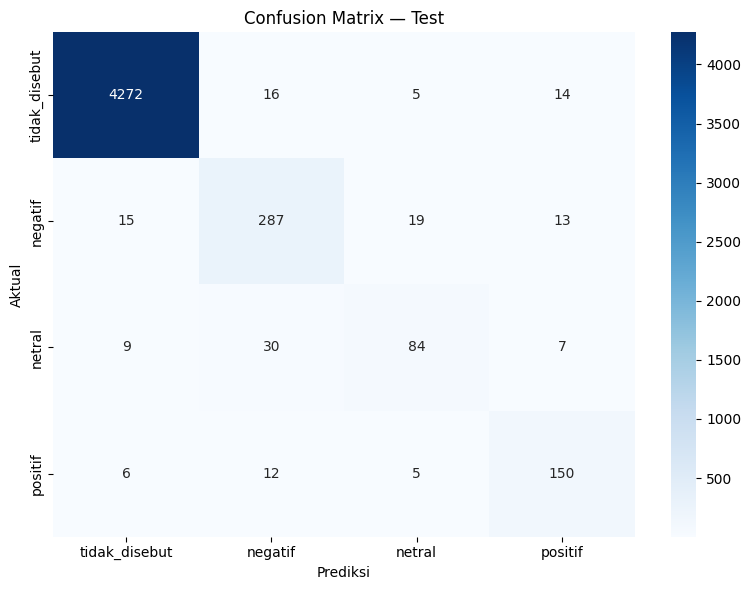

In [ ]:
best_model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)
best_model.eval()
eval_signature = inspect.signature(TrainingArguments.__init__).parameters
eval_kwargs = {
    "output_dir": str(OUTPUT_ROOT / "final_evaluation"),
    "per_device_eval_batch_size": 32,
    "fp16": True,
    "report_to": "none",
}
eval_kwargs = {k: v for k, v in eval_kwargs.items() if k in eval_signature}
eval_args = TrainingArguments(**eval_kwargs)
pred_kwargs = dict(
    model=best_model,
    args=eval_args,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)
if "processing_class" in inspect.signature(Trainer.__init__).parameters:
    pred_kwargs["processing_class"] = tokenizer
else:
    pred_kwargs["tokenizer"] = tokenizer
predictor = Trainer(**pred_kwargs)
test_output = predictor.predict(test_dataset)
y_true, y_pred = unpack_predictions(test_output)
test_metrics = calculate_metrics(y_true, y_pred)

print("Model terpilih:", best_trial["name"])
print("Test metrics:", json.dumps(test_metrics, ensure_ascii=False, indent=2))
print(classification_report(
    y_true, y_pred, labels=classes, target_names=LABEL_ORDER,
    digits=4, zero_division=0,
))

test_logits = test_output.predictions
if isinstance(test_logits, tuple):
    test_logits = test_logits[0]
probabilities = torch.softmax(
    torch.tensor(test_logits), dim=-1
).numpy()
test_predictions = test_long.copy()
test_predictions["sentiment_pred"] = [
    ID2LABEL[int(index)] for index in y_pred
]
test_predictions["confidence"] = probabilities.max(axis=1)
test_predictions.to_csv(
    OUTPUT_ROOT / "test_predictions.csv", index=False,
    encoding="utf-8-sig",
)

per_aspect_rows = []
for aspect, group in test_predictions.groupby("aspect", sort=False):
    indices = group.index.to_numpy()
    aspect_metrics = calculate_metrics(y_true[indices], y_pred[indices])
    per_aspect_rows.append({"aspect": aspect, **aspect_metrics})
per_aspect_metrics = pd.DataFrame(per_aspect_rows).sort_values(
    "f1_macro", ascending=False,
)
per_aspect_metrics.to_csv(
    OUTPUT_ROOT / "metrics_per_aspect.csv", index=False,
    encoding="utf-8-sig",
)
print("Metrik per aspek:")
display(per_aspect_metrics)

matrix = confusion_matrix(y_true, y_pred, labels=classes)
plt.figure(figsize=(8, 6))
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=LABEL_ORDER, yticklabels=LABEL_ORDER,
)
plt.title("Confusion Matrix — Test")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "confusion_matrix_test.png", dpi=160)
plt.show()

## 9. Contoh prediksi satu review

In [ ]:
def predict_absa(review_text: str):
    best_model.eval()
    device = next(best_model.parameters()).device
    aspect_names = list(ASPECT_TEXT)
    encoded = tokenizer(
        [review_text] * len(aspect_names),
        [ASPECT_TEXT[name] for name in aspect_names],
        padding=True, truncation=True,
        max_length=MAX_LENGTH, return_tensors="pt",
    ).to(device)
    with torch.no_grad():
        logits = best_model(**encoded).logits
    predicted_ids = logits.argmax(dim=-1).cpu().tolist()
    return {
        aspect: ID2LABEL[index]
        for aspect, index in zip(aspect_names, predicted_ids)
    }

example = "Aplikasinya cepat, tetapi kurirnya lambat dan voucher tidak bisa dipakai."
print(example)
print(json.dumps(predict_absa(example), ensure_ascii=False, indent=2))

Aplikasinya cepat, tetapi kurirnya lambat dan voucher tidak bisa dipakai.
{
  "iklan_dan_konten": "tidak_disebut",
  "pengiriman_dan_kurir": "negatif",
  "performa_aplikasi": "positif",
  "akun_login_keamanan": "tidak_disebut",
  "pembayaran_cod_dan_keuangan": "tidak_disebut",
  "promo_voucher_harga_dan_biaya": "negatif",
  "penjual_dan_kualitas_produk": "tidak_disebut",
  "retur_refund_dan_layanan": "tidak_disebut"
}


## 10. Simpan hasil dan download ZIP

In [ ]:
final_summary = {
    "dataset_file": DATA_PATH.name,
    "dataset_sha256": DATA_SHA256,
    "seed": SEED,
    "base_model": MODEL_NAME,
    "train_review_count": len(train_wide),
    "validation_review_count": len(val_wide),
    "test_review_count": len(test_wide),
    "max_length": MAX_LENGTH,
    "best_trial": best_trial,
    "test_metrics": test_metrics,
    "aspect_columns": ASPECT_COLUMNS,
    "aspect_text": ASPECT_TEXT,
    "label2id": LABEL2ID,
    "id2label": ID2LABEL,
}
for path in [OUTPUT_ROOT / "hasil_tuning.json", MODEL_DIR / "absa_config.json"]:
    with open(path, "w", encoding="utf-8") as file:
        json.dump(final_summary, file, ensure_ascii=False, indent=2)
with open(OUTPUT_ROOT / "test_metrics.json", "w", encoding="utf-8") as file:
    json.dump(test_metrics, file, ensure_ascii=False, indent=2)

zip_path = shutil.make_archive(
    str(Path("/content") / f"ABSA_IndoBERT_Tuning_{RUN_ID}"),
    "zip", root_dir=str(OUTPUT_ROOT),
)
print("ZIP:", zip_path)
print(f"Ukuran: {Path(zip_path).stat().st_size / (1024**2):.1f} MB")
from google.colab import files
files.download(zip_path)

ZIP: /content/ABSA_IndoBERT_Tuning_20261003_044443.zip
Ukuran: 442.6 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>